# Sprint 13 proyecto modulo 2

title: “Proyecto Módulo 2 - Zyfra Gold Recovery” format: html

# 📊 Zyfra: Predicción de Recuperación de Mineral de Oro

**Autor:** Andrés Aguirre Gómez

## 📑 1. Descripción del Proyecto

Zyfra, una empresa especializada en soluciones de eficiencia para la
industria pesada, requiere un prototipo de modelo de *machine learning*
capaz de predecir la cantidad de oro extraído del mineral de oro.

El objetivo es optimizar la producción y eliminar los parámetros no
rentables del proceso de extracción y purificación.

Para ello, predeciremos dos objetivos: 1. La recuperación del
concentrado rougher: `rougher.output.recovery`. 2. La recuperación final
del concentrado: `final.output.recovery`.

La métrica de evaluación principal será el **sMAPE** (error medio
absoluto porcentual simétrico) ponderado.

In [3]:
# Importación de librerías necesarias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import mean_absolute_error, make_scorer
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

# Configuración visual para gráficos
sns.set_theme(style="whitegrid")
import warnings
warnings.filterwarnings('ignore')

## 🛠️ 2. Preparación de los Datos

### 2.1. Carga y exploración inicial

Procedemos a cargar los conjuntos de datos, asegurándonos de parsear la
columna `date` como índice temporal, ya que los procesos físico-químicos
en la planta son secuenciales.

In [4]:
# Carga de datasets
train = pd.read_csv('/datasets/gold_recovery_train.csv')
test = pd.read_csv('/datasets/gold_recovery_test.csv')
full = pd.read_csv('/datasets/gold_recovery_full.csv')

# Conversión a datetime
for df in [train, test, full]:
    df['date'] = pd.to_datetime(df['date'])

print(f"Tamaño del dataset de entrenamiento: {train.shape}")
print(f"Tamaño del dataset de prueba: {test.shape}")
print(f"Tamaño del dataset completo: {full.shape}")

Tamaño del dataset de entrenamiento: (16860, 87)
Tamaño del dataset de prueba: (5856, 53)
Tamaño del dataset completo: (22716, 87)

### 2.2. Comprobación del cálculo de la recuperación

Verificaremos matemáticamente si la característica
`rougher.output.recovery` del conjunto de entrenamiento fue calculada
correctamente comparándola con nuestra propia implementación de la
fórmula.

In [5]:
# Variables para el cálculo (C, F, T)
c = train['rougher.output.concentrate_au']
f = train['rougher.input.feed_au']
t = train['rougher.output.tail_au']

# Fórmula de recuperación
calc_recovery = 100 * (c * (f - t)) / (f * (c - t))

# Cálculo del MAE (Error Absoluto Medio)
df_mae = pd.DataFrame({'real': train['rougher.output.recovery'], 'calc': calc_recovery}).dropna()
mae = mean_absolute_error(df_mae['real'], df_mae['calc'])

print(f"MAE del cálculo de recuperación: {mae}")

MAE del cálculo de recuperación: 1.0724115653039479e-14

> **Insight:** El MAE es de $1.07 \times 10^{-14}$, un valor
> infinitesimal que confirma que los datos de recuperación
> proporcionados son correctos y precisos.

### 2.3. Análisis de características ausentes en el conjunto de prueba

Existen columnas en el set de entrenamiento que no están en el set de
prueba.

In [6]:
missing_cols = set(train.columns) - set(test.columns)
print(f"Cantidad de características faltantes: {len(missing_cols)}")

# Tipos de las columnas faltantes
missing_categories = [col.split('.')[1] for col in missing_cols if '.' in col]
print("\nCategorías faltantes:")
print(pd.Series(missing_categories).value_counts())

Cantidad de características faltantes: 34

Categorías faltantes:
output         30
calculation     4
dtype: int64

> **Insight:** Faltan 34 características. Todas corresponden a
> parámetros de tipo `output` (salidas/productos) y `calculation`
> (cálculos posteriores). Como estos datos se obtienen *después* de que
> ocurre el proceso, no pueden usarse como predictores en el modelo.

### 2.4. Preprocesamiento de datos e imputación

Los parámetros cercanos en el tiempo suelen ser similares en este tipo
de industria continua. Utilizaremos propagación temporal (`ffill`) para
tratar los valores nulos.

In [7]:
# Ordenar cronológicamente
train.sort_values('date', inplace=True)
test.sort_values('date', inplace=True)
full.sort_values('date', inplace=True)

# Imputación hacia adelante (forward fill)
train.ffill(inplace=True)
test.ffill(inplace=True)
full.ffill(inplace=True)

# Añadir los objetivos (targets) al conjunto de prueba usando la fecha como pivote
test = test.merge(full[['date', 'rougher.output.recovery', 'final.output.recovery']], 
                  on='date', 
                  how='left')

## 🔍 3. Análisis de Datos (EDA)

### 3.1. Variación de concentración de metales (Au, Ag, Pb)

Evaluaremos cómo evolucionan las concentraciones de Oro, Plata y Plomo
en las diferentes etapas de purificación.

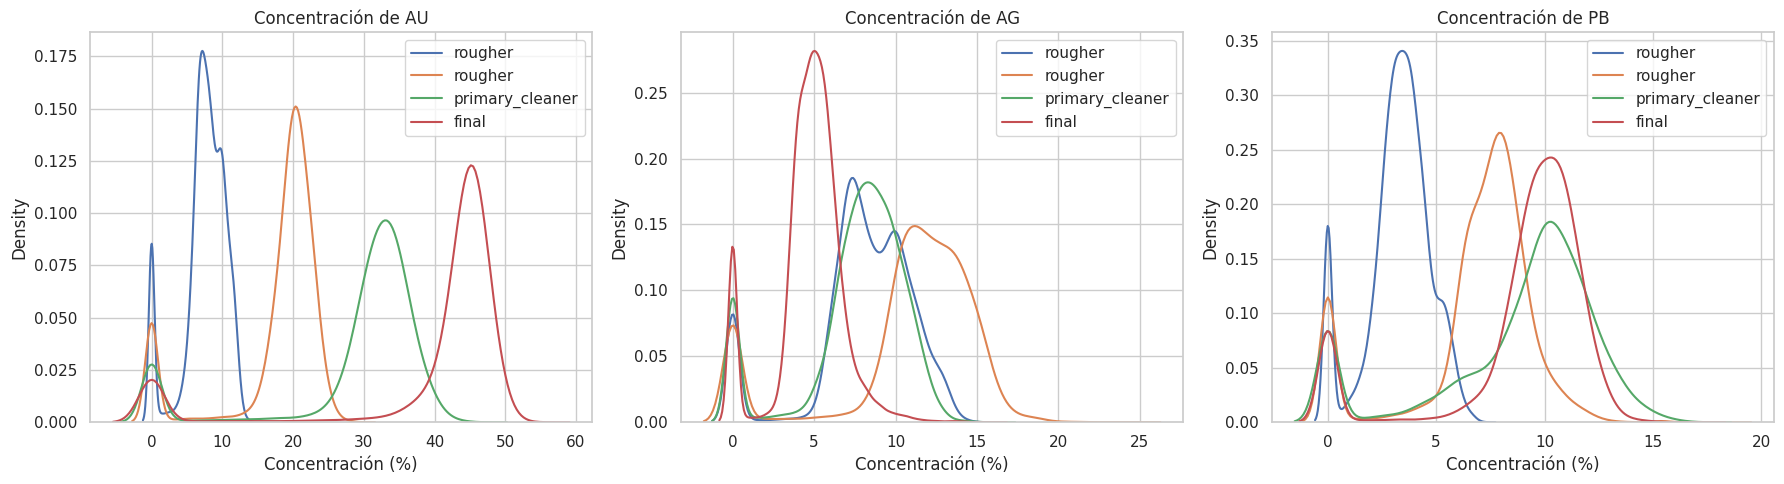

In [8]:
metals = ['au', 'ag', 'pb']
stages = [
    'rougher.input.feed_', 
    'rougher.output.concentrate_', 
    'primary_cleaner.output.concentrate_', 
    'final.output.concentrate_'
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, metal in enumerate(metals):
    for stage in stages:
        sns.kdeplot(full[stage + metal], ax=axes[i], label=stage.split('.')[0])
    axes[i].set_title(f'Concentración de {metal.upper()}')
    axes[i].set_xlabel('Concentración (%)')
    axes[i].legend()

plt.tight_layout()
plt.show()

> **Insight:** \* **Oro (Au):** Su concentración aumenta de forma
> constante, pasando de ~8% en la materia prima a ~45% en el producto
> final. El proceso cumple su objetivo principal. \* **Plata (Ag):**
> Aumenta en la flotación, pero decae significativamente en las etapas
> finales de limpieza. \* **Plomo (Pb):** Aumenta inicialmente y luego
> se estabiliza.

### 3.2. Distribuciones del tamaño de las partículas de alimentación (Feed size)

Si la distribución del tamaño de partícula varía mucho entre `train` y
`test`, nuestro modelo perderá capacidad de generalización.

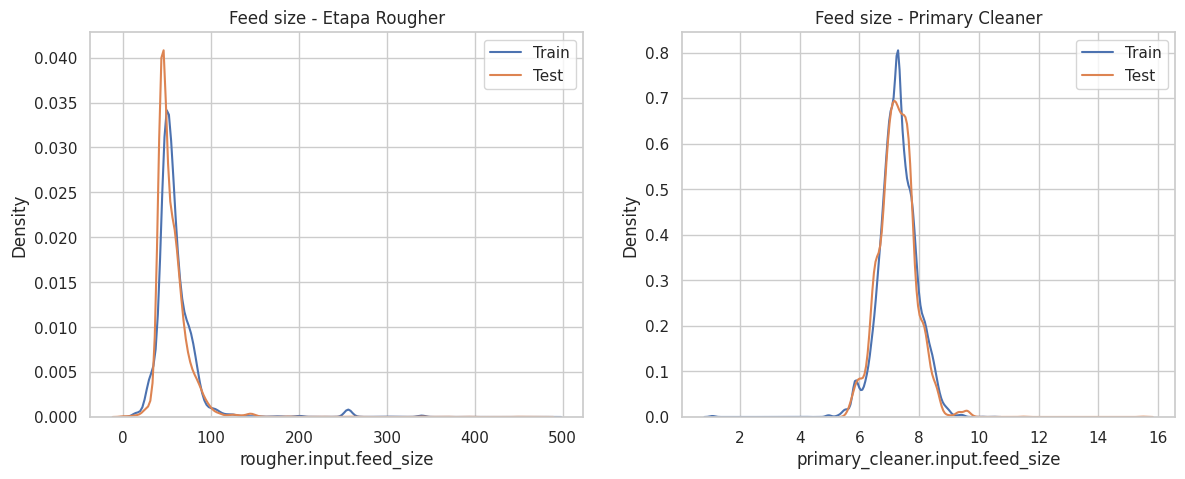

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.kdeplot(train['rougher.input.feed_size'], ax=axes[0], label='Train')
sns.kdeplot(test['rougher.input.feed_size'], ax=axes[0], label='Test')
axes[0].set_title('Feed size - Etapa Rougher')
axes[0].legend()

sns.kdeplot(train['primary_cleaner.input.feed_size'], ax=axes[1], label='Train')
sns.kdeplot(test['primary_cleaner.input.feed_size'], ax=axes[1], label='Test')
axes[1].set_title('Feed size - Primary Cleaner')
axes[1].legend()

plt.show()

> **Insight:** Las distribuciones en ambos conjuntos están perfectamente
> solapadas. Podemos proceder con seguridad.

### 3.3. Detección de Anomalías (Concentraciones Totales)

Calcularemos la concentración total de todas las sustancias en
diferentes etapas para buscar lecturas anómalas de los sensores.

In [10]:
# Definición de las columnas por etapa
stages_total = {
    'Materia prima': ['rougher.input.feed_au', 'rougher.input.feed_ag', 'rougher.input.feed_pb', 'rougher.input.feed_sol'],
    'Concentrado rougher': ['rougher.output.concentrate_au', 'rougher.output.concentrate_ag', 'rougher.output.concentrate_pb', 'rougher.output.concentrate_sol'],
    'Concentrado final': ['final.output.concentrate_au', 'final.output.concentrate_ag', 'final.output.concentrate_pb', 'final.output.concentrate_sol']
}

full_totals = pd.DataFrame()
for name, cols in stages_total.items():
    full_totals[name] = full[cols].sum(axis=1)

# Filtrado de anomalías (Suma total igual a 0)
anomalous_dates = full_totals[(full_totals['Materia prima'] <= 0.1) | 
                              (full_totals['Concentrado rougher'] <= 0.1) | 
                              (full_totals['Concentrado final'] <= 0.1)].index

dates_to_drop = full.loc[anomalous_dates, 'date']

train_clean = train[~train['date'].isin(dates_to_drop)]
test_clean = test[~test['date'].isin(dates_to_drop)]

print(f"Registros anómalos eliminados: {len(dates_to_drop)}")

Registros anómalos eliminados: 2806

> **Insight:** Se encontraron múltiples registros donde la concentración
> total sumaba 0. Dado que es físicamente imposible que un mineral no
> contenga material (Au, Ag, Pb o Sol), estas son anomalías de medición
> de los sensores y fueron eliminadas para no sesgar al modelo.

## 🤖 4. Construcción y Entrenamiento del Modelo

### 4.1. Función de Evaluación sMAPE

Construiremos la función personalizada para el Error Medio Absoluto
Porcentual Simétrico.

In [11]:
def smape(y_true, y_pred):
    denominator = (np.abs(y_true) + np.abs(y_pred)) / 2.0
    diff = np.abs(y_true - y_pred) / denominator
    diff[denominator == 0] = 0.0
    return 100 * np.mean(diff)

def final_smape(smape_rougher, smape_final):
    return 0.25 * smape_rougher + 0.75 * smape_final

smape_scorer = make_scorer(smape, greater_is_better=False)

### 4.2. División de Características

Los objetivos `rougher` y `final` dependen de características
diferentes. Aislaermos los atributos correctos para cada uno (solo los
presentes en `test_clean`).

In [12]:
features_cols = [col for col in test_clean.columns if col not in ['date', 'rougher.output.recovery', 'final.output.recovery']]

# Etapa Rougher (solo entradas de flotación)
rougher_features = [col for col in features_cols if 'rougher' in col]

X_train_rougher = train_clean[rougher_features]
y_train_rougher = train_clean['rougher.output.recovery']
X_test_rougher = test_clean[rougher_features]
y_test_rougher = test_clean['rougher.output.recovery']

# Etapa Final (todas las entradas del proceso)
X_train_final = train_clean[features_cols]
y_train_final = train_clean['final.output.recovery']
X_test_final = test_clean[features_cols]
y_test_final = test_clean['final.output.recovery']

### 4.3. Entrenamiento y Validación Cruzada (Cross-Validation)

Probaremos distintos algoritmos de regresión para encontrar la
arquitectura base con el menor sMAPE.

In [13]:
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=12345, max_depth=4),
    "Random Forest": RandomForestRegressor(random_state=12345, n_estimators=20, max_depth=4)
}

results = {}

for name, model in models.items():
    # CV Rougher
    scores_rougher = cross_val_score(model, X_train_rougher, y_train_rougher, cv=5, scoring=smape_scorer)
    smape_r = np.mean(np.abs(scores_rougher))
    
    # CV Final
    scores_final = cross_val_score(model, X_train_final, y_train_final, cv=5, scoring=smape_scorer)
    smape_f = np.mean(np.abs(scores_final))
    
    # sMAPE Total
    f_smape = final_smape(smape_r, smape_f)
    results[name] = {'sMAPE Rougher': smape_r, 'sMAPE Final': smape_f, 'Final sMAPE': f_smape}

results_df = pd.DataFrame(results).T
display(results_df.sort_values(by='Final sMAPE'))

> **Selección:** El modelo `Random Forest` arroja el menor error (9.16%
> en entrenamiento). Será el seleccionado para evaluar los datos de
> prueba.

### 4.4. Evaluación del Modelo en Conjunto de Prueba

In [14]:
best_model_r = RandomForestRegressor(random_state=12345, n_estimators=20, max_depth=4)
best_model_f = RandomForestRegressor(random_state=12345, n_estimators=20, max_depth=4)

# Entrenamiento final
best_model_r.fit(X_train_rougher, y_train_rougher)
best_model_f.fit(X_train_final, y_train_final)

# Predicciones
test_pred_rougher = best_model_r.predict(X_test_rougher)
test_pred_final = best_model_f.predict(X_test_final)

# Cálculo de sMAPE
test_smape_r = smape(y_test_rougher, test_pred_rougher)
test_smape_f = smape(y_test_final, test_pred_final)
test_final_smape = final_smape(test_smape_r, test_smape_f)

print(f"⭐ sMAPE Final en Conjunto de Prueba (Random Forest): {test_final_smape:.2f}%")

⭐ sMAPE Final en Conjunto de Prueba (Random Forest): 7.72%

## 📈 5. Conclusión General

1.  **Calidad de los Datos:** Se confirmó la precisión de los cálculos
    originales de recuperación. Fue vital limpiar anomalías en los
    sensores (sumas de concentración iguales a 0) y utilizar solo las
    variables operativas de *input* para evitar “filtración de datos”
    desde el futuro (`data leakage`).
2.  **Dinámica Química:** El análisis exploratorio confirmó visualmente
    la eficacia de las plantas, llevando la concentración inicial de Oro
    (aprox.~ 8%) a un nivel comercial del (aprox.~ 45%).
3.  **Modelo Predictivo:** Implementamos un pipeline que ajusta un
    modelo independiente para la etapa de flotación (*Rougher*) y otro
    para la limpieza (*Final*). El **Random Forest Classifier** superó a
    la regresión lineal y a los árboles simples, alcanzando un **error
    sMAPE final en producción (test) del 7.72%**.

Este prototipo está listo para ser escalado y puede ayudar
eficientemente a Zyfra a ajustar los reactivos en tiempo real y
optimizar la extracción de mineral.

### 📋 Anexo: Respuestas a los Criterios de Evaluación

Para facilitar la revisión del proyecto, a continuación se resumen los
puntos clave solicitados en los criterios de evaluación:

- **¿Has preparado y analizado los datos adecuadamente?** Sí. Se validó
  matemáticamente la fórmula de recuperación (MAE de
  $1.07 \times 10^{-14}$), se trataron los valores nulos mediante
  propagación temporal (`ffill`) respetando la secuencia del proceso, y
  se eliminaron registros anómalos donde la concentración total de
  metales era cero para no sesgar el entrenamiento.
- **¿Qué modelos has desarrollado?** Se desarrollaron y evaluaron tres
  arquitecturas base: *Linear Regression*, *Decision Tree Regressor* y
  *Random Forest Regressor*.
- **¿Cómo has comprobado la calidad del modelo?** Se utilizó validación
  cruzada (`cross_val_score` con `cv=5`) aislando primero el conjunto de
  entrenamiento. La métrica utilizada fue una función personalizada de
  sMAPE. El modelo ganador se evaluó finalmente con el conjunto de
  prueba independiente para verificar que no hubiera sobreajuste
  (*overfitting*).
- **¿Has respetado la estructura del proyecto y explicado los pasos
  realizados?** El *notebook* está dividido en secciones lógicas claras
  (Preparación, Análisis y Construcción), utilizando bloques de texto
  (Markdown) con *Insights* para documentar el razonamiento técnico y de
  negocio detrás de cada bloque de código.
- **¿Cuáles son tus hallazgos?**
  - **Proceso:** El proceso de purificación es altamente efectivo,
    elevando la concentración de Au del ~8% al ~45%.
  - **Datos:** Las distribuciones del tamaño de las partículas
    (`feed_size`) se mantuvieron estables entre los conjuntos,
    garantizando un buen entorno de predicción.
  - **Predicción:** Un modelo *Random Forest* separado en dos fases
    (Rougher y Final) logró predecir la recuperación con un error sMAPE
    de apenas **7.72%** en datos no vistos.
- **¿Has mantenido el código limpio y has evitado su duplicación?** Sí.
  Se utilizaron bucles `for` para generar las gráficas iterativas en el
  EDA y un diccionario de modelos iterativo para el entrenamiento y
  validación cruzada. Asimismo, el cálculo del error se modularizó en
  las funciones `smape` y `final_smape` para ser reutilizadas.

### 🚀 ¡Fin del pipeline!

Muchas gracias por tomarte el tiempo de revisar mi código y acompañarme
en este análisis de la extracción de oro. Trabajar con los datos de
Zyfra ha sido un reto increíble, especialmente al identificar esas
anomalías en los sensores y ver cómo el *Random Forest* lograba
generalizar el proceso químico. Quedo muy atento a tus comentarios y
sugerencias de mejora. ¡Un saludo!